In [3]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU: []


In [6]:
import tensorflow as tf
import cv2
import sklearn
import matplotlib


print("TensorFlow:", tf.__version__)
print("OpenCV:", cv2.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All required packages are available.")

TensorFlow: 2.21.0
OpenCV: 4.13.0
Scikit-learn: 1.8.0
All required packages are available.


In [7]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "violence_detector.h5",
    compile=False
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ time_distributed (TimeDistributed)   │ (None, 10, 62, 62, 32)      │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_1 (TimeDistributed) │ (None, 10, 31, 31, 32)      │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_2 (TimeDistributed) │ (None, 10, 29, 29, 64)      │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_3 (TimeDistributed) │ (None, 10, 14, 14, 64)      │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_4 (TimeDistributed) │ (None, 10, 12544)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 64)                  │       3,227,904 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 2)                   │             130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,251,586 (12.40 MB)

 Trainable params: 3,251,586 (12.40 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries loaded successfully")

Libraries loaded successfully


In [21]:
import os

VIOLENCE_DIR = r"C:\Users\Cnaan\OneDrive\Desktop\Violance project\dataset\violence"
NON_VIOLENCE_DIR = r"C:\Users\Cnaan\OneDrive\Desktop\Violance project\dataset\non_violence"

print("Violence videos:", len(os.listdir(VIOLENCE_DIR)))
print("Non-Violence videos:", len(os.listdir(NON_VIOLENCE_DIR)))

Violence videos: 16
Non-Violence videos: 9


In [22]:
IMG_SIZE = 64
SEQUENCE_LENGTH = 10

def extract_frames(video_path):
    cap = cv2.VideoCapture(video_path)

    frames = []

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        return None

    # Select 10 equally spaced frames
    frame_indices = np.linspace(
        0,
        total_frames - 1,
        SEQUENCE_LENGTH
    ).astype(int)

    for index in frame_indices:

        cap.set(cv2.CAP_PROP_POS_FRAMES, index)

        ret, frame = cap.read()

        if not ret:
            cap.release()
            return None

        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame = cv2.resize(frame, (IMG_SIZE, IMG_SIZE))
        frame = frame.astype("float32") / 255.0

        frames.append(frame)

    cap.release()

    return np.array(frames)


In [23]:
sample_video = os.path.join(
    VIOLENCE_DIR,
    os.listdir(VIOLENCE_DIR)[0]
)

sample_frames = extract_frames(sample_video)

print("Video:", sample_video)
print("Frames shape:", sample_frames.shape)

Video: C:\Users\Cnaan\OneDrive\Desktop\Violance project\dataset\violence\V_100.mp4
Frames shape: (10, 64, 64, 3)


In [24]:
y_true = []
y_pred = []
probabilities = []

# -------------------------
# Violence = 1
# -------------------------
for filename in os.listdir(VIOLENCE_DIR):

    if not filename.lower().endswith((".mp4", ".avi", ".mov", ".mkv")):
        continue

    video_path = os.path.join(VIOLENCE_DIR, filename)

    frames = extract_frames(video_path)

    if frames is None:
        print("Could not process:", filename)
        continue

    # Add batch dimension
    input_data = np.expand_dims(frames, axis=0)

    prediction = model.predict(input_data, verbose=0)

    probabilities.append(prediction[0])

    # Two-class output
    predicted_class = np.argmax(prediction[0])

    y_true.append(1)
    y_pred.append(predicted_class)


# -------------------------
# Non-Violence = 0
# -------------------------
for filename in os.listdir(NON_VIOLENCE_DIR):

    if not filename.lower().endswith((".mp4", ".avi", ".mov", ".mkv")):
        continue

    video_path = os.path.join(NON_VIOLENCE_DIR, filename)

    frames = extract_frames(video_path)

    if frames is None:
        print("Could not process:", filename)
        continue

    input_data = np.expand_dims(frames, axis=0)

    prediction = model.predict(input_data, verbose=0)

    probabilities.append(prediction[0])

    predicted_class = np.argmax(prediction[0])

    y_true.append(0)
    y_pred.append(predicted_class)


y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Videos evaluated:", len(y_true))

Videos evaluated: 25


In [25]:
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

print("=" * 40)
print("MODEL EVALUATION RESULTS")
print("=" * 40)

print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1 Score  : {f1 * 100:.2f}%")

MODEL EVALUATION RESULTS
Accuracy  : 84.00%
Precision : 80.00%
Recall    : 100.00%
F1 Score  : 88.89%


In [26]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Non-Violence", "Violence"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

Non-Violence       1.00      0.56      0.71         9
    Violence       0.80      1.00      0.89        16

    accuracy                           0.84        25
   macro avg       0.90      0.78      0.80        25
weighted avg       0.87      0.84      0.83        25



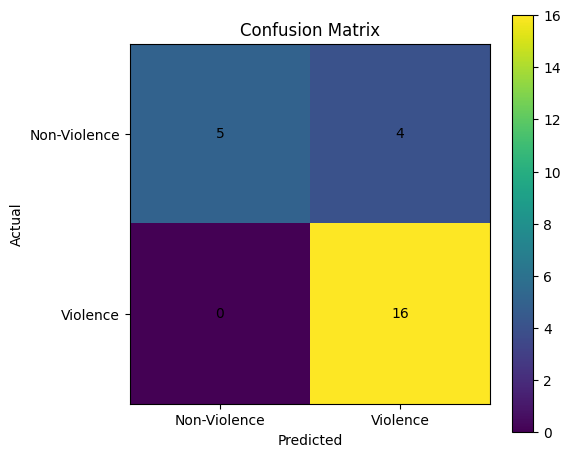

In [28]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))

plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix")
plt.colorbar()

classes = ["Non-Violence", "Violence"]

plt.xticks([0, 1], classes)
plt.yticks([0, 1], classes)

plt.xlabel("Predicted")
plt.ylabel("Actual")

# Display numbers inside the matrix
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [30]:
print("Model input shape:", model.input_shape)
print("Model output shape:", model.output_shape)

Model input shape: (None, 10, 64, 64, 3)
Model output shape: (None, 2)


In [33]:
# import os
# import numpy as np

# print("========== VIOLENCE VIDEOS ==========")

# for filename in os.listdir(VIOLENCE_DIR):
#     if not filename.lower().endswith((".mp4", ".avi", ".mov", ".mkv")):
#         continue

#     video_path = os.path.join(VIOLENCE_DIR, filename)

#     frames = extract_frames(video_path)

#     if frames is None:
#         print("Could not process:", filename)
#         continue

#     input_data = np.expand_dims(frames, axis=0)
#     prediction = model.predict(input_data, verbose=0)[0]
#     predicted_class = np.argmax(prediction)

#     print(
#         filename,
#         "->",
#         prediction,
#         "Class:",
#         predicted_class
#     )


# print("\n========== NON-VIOLENCE VIDEOS ==========")

# for filename in os.listdir(NON_VIOLENCE_DIR):
#     if not filename.lower().endswith((".mp4", ".avi", ".mov", ".mkv")):
#         continue

#     video_path = os.path.join(NON_VIOLENCE_DIR, filename)

#     frames = extract_frames(video_path)

#     if frames is None:
#         print("Could not process:", filename)
#         continue

#     input_data = np.expand_dims(frames, axis=0)
#     prediction = model.predict(input_data, verbose=0)[0]
#     predicted_class = np.argmax(prediction)

#     print(
#         filename,
#         "->",
#         prediction,
#         "Class:",
#         predicted_class
#     )

========== VIOLENCE VIDEOS ==========
V_100.mp4 -> [0.01507763 0.9849223 ] Class: 1
V_1000.mp4 -> [0.00790157 0.99209845] Class: 1
V_103.mp4 -> [0.00117121 0.9988288 ] Class: 1
V_105.mp4 -> [0.00112415 0.9988758 ] Class: 1
V_108.mp4 -> [0.00121534 0.9987847 ] Class: 1
V_109.mp4 -> [0.00114393 0.99885607] Class: 1
V_11.mp4 -> [0.00148898 0.998511  ] Class: 1
V_113.mp4 -> [0.00995804 0.990042  ] Class: 1
V_117.mp4 -> [0.001484 0.998516] Class: 1
V_118.mp4 -> [0.00147188 0.9985281 ] Class: 1
V_120.mp4 -> [0.00154003 0.99845994] Class: 1
V_121.mp4 -> [0.00152788 0.99847215] Class: 1
V_124.mp4 -> [0.01572717 0.98427284] Class: 1
V_140.mp4 -> [0.00850414 0.99149585] Class: 1
V_145.mp4 -> [0.17393076 0.8260693 ] Class: 1
V_147.mp4 -> [0.01102048 0.98897946] Class: 1

========== NON-VIOLENCE VIDEOS ==========
NV_1.mp4 -> [0.02390006 0.97609997] Class: 1
NV_10.mp4 -> [0.83793396 0.16206603] Class: 0
NV_100.mp4 -> [0.81476897 0.18523103] Class: 0
NV_12.mp4 -> [0.9833229  0.01667711] Class: 0
NV_

In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    pos_label=1
)

recall = recall_score(
    y_true,
    y_pred,
    pos_label=1
)

f1 = f1_score(
    y_true,
    y_pred,
    pos_label=1
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Non-Violence", "Violence"]
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Accuracy : 0.84
Precision: 0.8
Recall   : 1.0
F1 Score : 0.8888888888888888

Classification Report:
              precision    recall  f1-score   support

Non-Violence       1.00      0.56      0.71         9
    Violence       0.80      1.00      0.89        16

    accuracy                           0.84        25
   macro avg       0.90      0.78      0.80        25
weighted avg       0.87      0.84      0.83        25


Confusion Matrix:
[[ 5  4]
 [ 0 16]]
